<a href="https://colab.research.google.com/github/kyleonyonyi-a11y/AI/blob/main/Heatmap.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import pandas as pd

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (mean_squared_error, r2_score,confusion_matrix,ConfusionMatrixDisplay)

load diabetes dataset

In [9]:
diabetes=load_diabetes(as_frame=True)
df=diabetes.frame
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


draw correlation heat map

<function matplotlib.pyplot.show(close=None, block=None)>

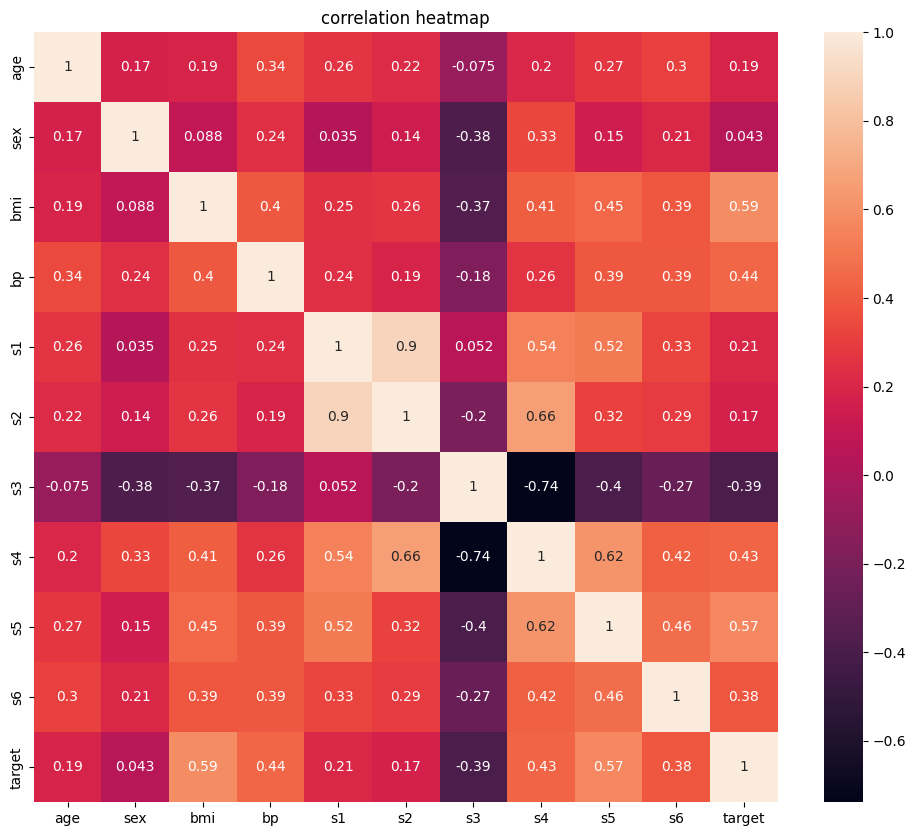

In [11]:
plt.figure(figsize=(12,10))
sns.heatmap(df.corr(),annot=True)
plt.title('correlation heatmap')
plt.show

1.which feature has the strongest positive correlation with the target?

2.which feature has the weakest correlation

1.BMI

2.SEX

Separate the independent variables (X), from the target variable

In [13]:
x=df.drop('target',axis=1)
y=df['target']

split the dataset into training and testing data

In [14]:
X_train, Xtest, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

The linear regression model

In [15]:
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

Make predictions

In [16]:
predictions=model.predict(Xtest)
print(predictions[:10])

[139.5475584  179.51720835 134.03875572 291.41702925 123.78965872
  92.1723465  258.23238899 181.33732057  90.22411311 108.63375858]


Evaluate the model

In [17]:
mse=mean_squared_error(y_test,predictions)
r2=r2_score(y_test,predictions)
print(f'mean squared error: {mse}')
print(f'r2 score: {r2}')

mean squared error: 2900.1936284934814
r2 score: 0.4526027629719195


draw a scatter plot

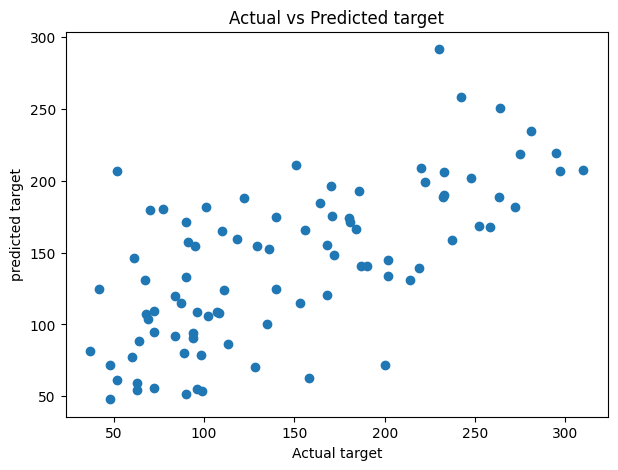

In [18]:
plt.figure(figsize=(7,5))
plt.scatter(y_test,predictions)
plt.xlabel('Actual target')
plt.ylabel('predicted target')
plt.title('Actual vs Predicted target')
plt.show()